# Figure 1B — CAID2 Disorder-PDB: MCC ranking

Disorder predictors from CAID2 ranked by per-residue MCC on the Disorder-PDB reference set, with metapredict V1, V2 and V3 highlighted.

**How it is made.** MCC is recomputed here from the CAID2 per-residue prediction files (`data/caid2/*.caid` in the shared data directory) against `data/caid_references/caid2_disorder_pdb.fasta`. Methods that submitted binary calls are scored on those calls; methods without binary calls are only included where a published disorder threshold exists (AlphaFold-rsa 0.581, AlphaFold-disorder 0.312, RONN 0.5). metapredict V1–V3 are scored the same way from metapredict 3.1.0 predictions of the CAID2 targets (`data/metapredict_caid/` in the shared data directory), using 3.1.0's default binary calls (residues inside predicted IDRs are disordered). The metapredict file distributed by CAID2 is not used.

**Output:** `figures/figure_1B.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid_mcc import (metapredict_mcc, plot_mcc_panel, read_caid_convert_get_MCC,
                      read_caid_convert_get_MCC_allow_altered_cutoff, read_caid_seq_disorder)
from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

CAID2_DIR = shared_data_path('caid2')
caid2_dat = read_caid_seq_disorder(str(shared_data_path('caid_references', 'caid2_disorder_pdb.fasta')))

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# Predictors that submitted binarized calls. FoldUnfold submitted only binary calls
# (empty raw-score column), so it belongs here.
caid2_predictors_with_binarized_scores = [
    'VSL2', 'AUCpred-no-profile', 'SPOT-Disorder', 'SPOT-Disorder-Single', 'flDPnn', 'pyHCA', 'DeepIDP-2L',
    'AIUPred', 'ESpritz-X', 'ENSHROUD-all', 'PredIDR-short', 'IDP-Fusion', 'IsUnstruct', 'DisoPred', 'SETH-1',
    'MobiDB-lite', 'DISOPRED3-diso', 'SPOT-Disorder2', 'IUPred3', 'ESpritz-N', 'PreDisorder', 'APOD', 'flDPlr2',
    'SETH-0', 'AUCpred-profile', 'Dispredict3', 'flDPtr', 'PredIDR-long', 's2D', 'ESpritz-D', 'flDPnn2',
    'Dispredict2', 'FoldUnfold']

# Predictors without binarized calls but with a published disorder threshold
caid2_predictors_without_binarized_scores = {'AlphaFold-rsa': 0.581, 'AlphaFold-disorder': 0.312, 'RONN': 0.5}

caid2_disprot_pdb_mcc = {}
for name in caid2_predictors_with_binarized_scores:
    caid2_disprot_pdb_mcc[name] = read_caid_convert_get_MCC(CAID2_DIR / f'{name}.caid', caid2_dat)
for name, cutoff in caid2_predictors_without_binarized_scores.items():
    caid2_disprot_pdb_mcc[name] = read_caid_convert_get_MCC_allow_altered_cutoff(
        CAID2_DIR / f'{name}.caid', caid2_dat, cutoff=cutoff)

# metapredict V1-V3, scored from 3.1.0 predictions
caid2_disprot_pdb_mcc.update(metapredict_mcc('caid2', caid2_dat))

print(f'{len(caid2_disprot_pdb_mcc)} predictors scored')
for name in ['metapredict V1', 'metapredict V2', 'metapredict V3']:
    print(f'{name}: MCC = {caid2_disprot_pdb_mcc[name]:.3f}')

39 predictors scored
metapredict V1: MCC = 0.692
metapredict V2: MCC = 0.768
metapredict V3: MCC = 0.769


Wrote figures/figure_1B.pdf


PosixPath('figures/figure_1B.pdf')

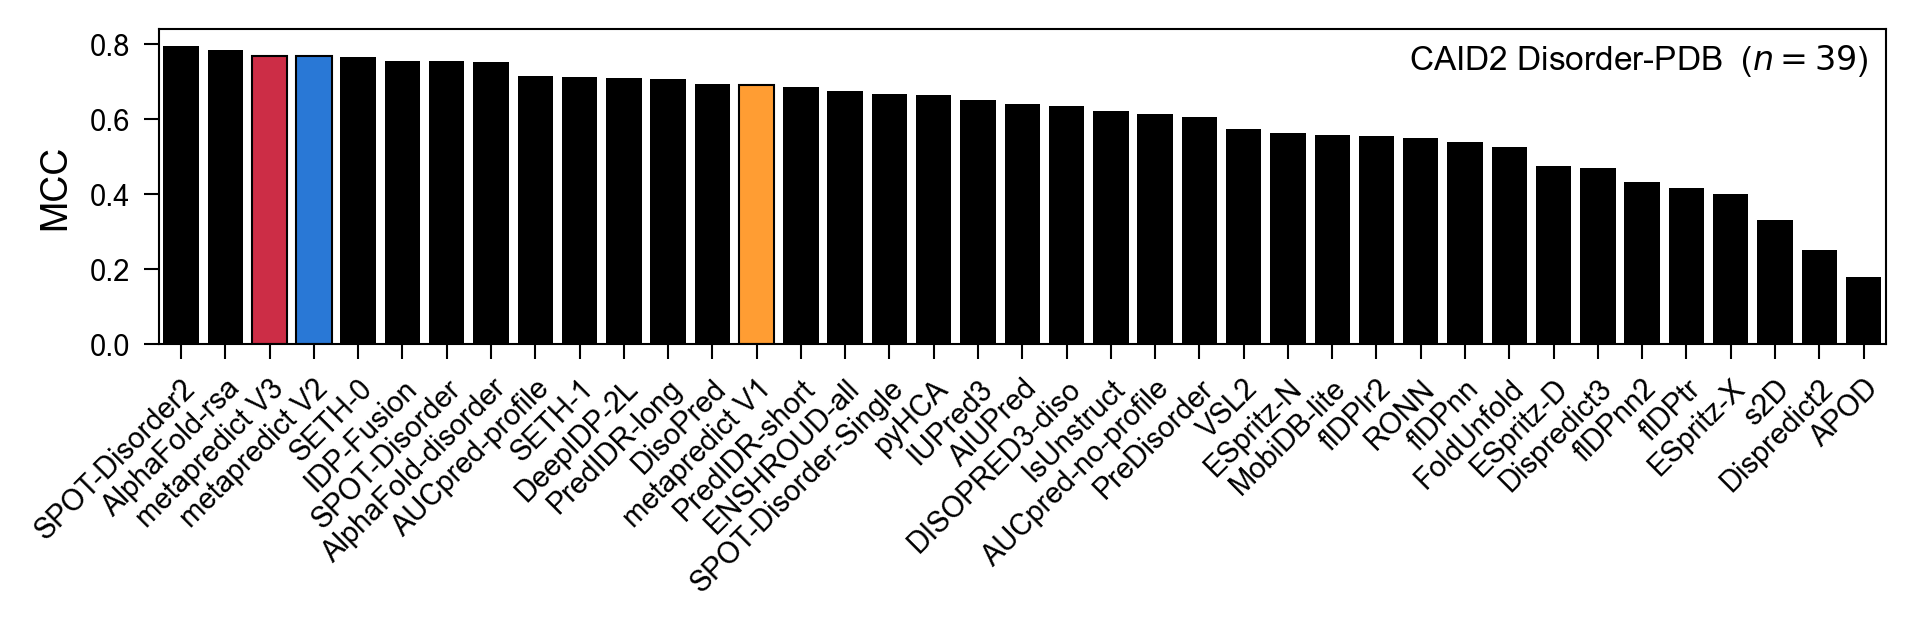

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
plot_mcc_panel(ax, caid2_disprot_pdb_mcc, 'CAID2 Disorder-PDB')
plt.tight_layout()
save_panel(fig, 'figure_1B')